In [ ]:
from pathlib import Path
import re
import pickle

import numpy as np
import matplotlib.pyplot as plt
import umap

from tqdm.auto import tqdm
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D


ROOT = Path.cwd()

RAW_ROOT = (
    Path.home()
    / "scratch"
    / "binary_maze_data"
    / "REWARD_DRIVEN_1000"
)

PREFIX = "REWARD_DRIVEN_1000_runs_slurm_20_window_agent_rew_p_"

P_VALUES = [0.0, 0.02]
SEEDS = list(range(10))
WINDOW = (0.2, 0.22)

UMAP_DIR = ROOT / "paper_figures" / "agent_prior_umaps"
UMAP_DIR.mkdir(parents=True, exist_ok=True)

UMAP_PARAMS = dict(
    n_components=2,
    n_neighbors=30,
    min_dist=0.1,
    metric="euclidean",
    random_state=42,
)


def format_p(p):
    s = f"{float(p):.3f}".rstrip("0")
    return s if not s.endswith(".") else s + "0"


def get_run_dir(p, seed):
    return (
        RAW_ROOT
        / f"{PREFIX}{format_p(p)}"
        / str(seed)
    )


def get_umap_path(p, seed):
    p_str = format_p(p).replace(".", "p")
    return UMAP_DIR / f"agent_zp_p_{p_str}_seed_{seed}.pkl"


def find_bout_files(run_dir):
    files = []

    for path in run_dir.glob("bout_*_metrics.npz"):
        match = re.fullmatch(
            r"bout_(\d+)_metrics\.npz",
            path.name,
        )
        if match:
            files.append((int(match.group(1)), path))

    return sorted(files)

In [ ]:
def load_agent_window(p, seed):

    run_dir = get_run_dir(p, seed)

    if not run_dir.is_dir():
        raise FileNotFoundError(run_dir)

    files = find_bout_files(run_dir)

    if not files:
        raise ValueError(f"No bout files in {run_dir}")

    # Select 0.2–0.3 of the experiment
    n_bouts = len(files)

    start = int(round(WINDOW[0] * n_bouts))
    end = int(round(WINDOW[1] * n_bouts))

    selected = files[start:end]

    z_parts = []
    nodes_parts = []
    prev_nodes_parts = []

    for bout_id, path in selected:

        with np.load(path, allow_pickle=False) as data:

            z_p = np.asarray(data["z_p"])
            obs = np.asarray(
                data["obs_full"],
                dtype=int,
            )

        # Each z_p corresponds to one transition:
        # obs[t] -> obs[t+1]

        if len(z_p) != len(obs) - 1:
            raise ValueError(
                f"Alignment mismatch in {path}: "
                f"z_p={len(z_p)}, obs={len(obs)}"
            )

        z_parts.append(z_p)

        # Target nodes
        nodes_parts.append(obs[1:])

        # Source nodes
        prev_nodes_parts.append(obs[:-1])

    Z = np.concatenate(z_parts, axis=0)
    nodes = np.concatenate(nodes_parts)
    prev_nodes = np.concatenate(prev_nodes_parts)

    return Z, nodes, prev_nodes

In [9]:
for p in P_VALUES:

    for seed in tqdm(SEEDS, desc=f"p={p}"):

        save_path = get_umap_path(p, seed)

        # Reuse previously calculated embeddings
#         if save_path.exists():
#             print(f"Already exists: p={p}, seed={seed}")
#             continue

        # Load saved priors and corresponding nodes
        Z, nodes, prev_nodes = load_agent_window(
            p, seed
        )

        # Fit UMAP
        reducer = umap.UMAP(**UMAP_PARAMS)

        Z_umap = reducer.fit_transform(Z)

        # Directions from node IDs ONLY
        outward = nodes > prev_nodes
        inward = nodes < prev_nodes

        saved = {
            "Z_umap": Z_umap,
            "nodes_used": nodes,
            "prev_nodes_used": prev_nodes,
            "p": p,
            "seed": seed,
            "window": WINDOW,
        }

        with open(save_path, "wb") as f:
            pickle.dump(saved, f)

        print(
            f"p={p}, seed={seed} | "
            f"points={len(Z):,} | "
            f"outward={outward.sum():,} | "
            f"inward={inward.sum():,}"
        )

print("All UMAP embeddings saved.")

p=0.0:   0%|          | 0/10 [00:00<?, ?it/s]

/storage/home/hcoda1/9/kshilova3/.local/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


p=0.0, seed=0 | points=6,999 | outward=3,686 | inward=3,313


/storage/home/hcoda1/9/kshilova3/.local/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


p=0.0, seed=1 | points=6,638 | outward=3,516 | inward=3,122


/storage/home/hcoda1/9/kshilova3/.local/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


... (32 outputs left out)

/storage/home/hcoda1/9/kshilova3/.local/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


p=0.02, seed=8 | points=6,807 | outward=3,508 | inward=3,299


/storage/home/hcoda1/9/kshilova3/.local/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


p=0.02, seed=9 | points=7,035 | outward=3,717 | inward=3,318
All UMAP embeddings saved.


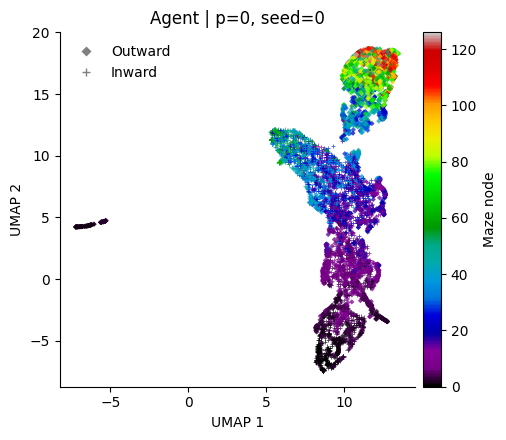

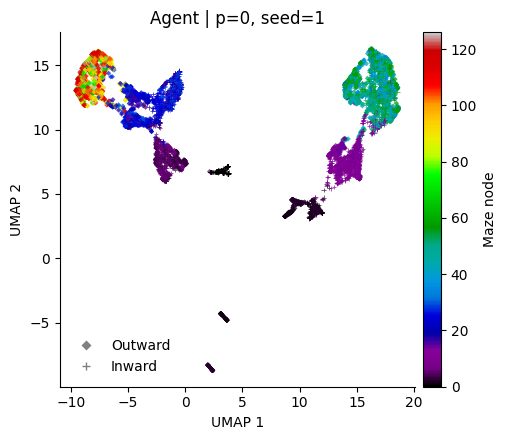

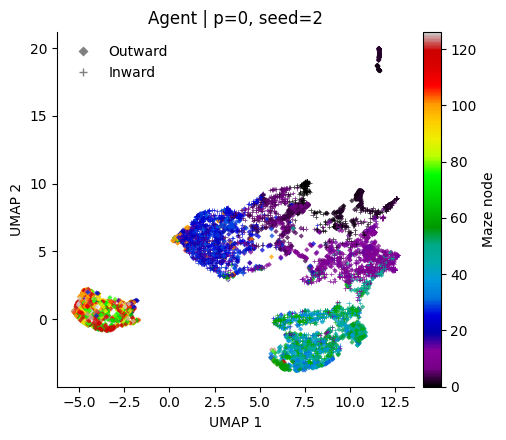

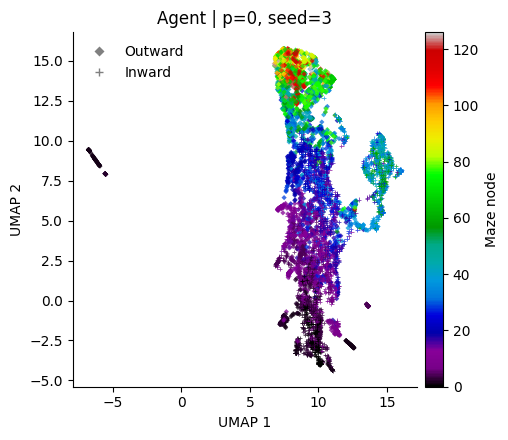

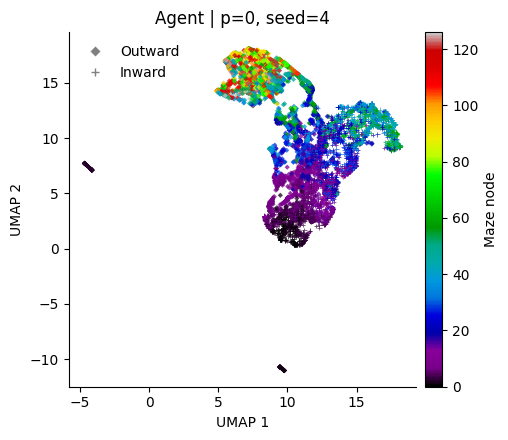

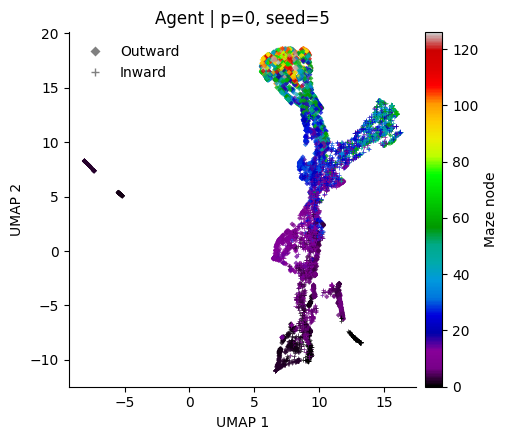

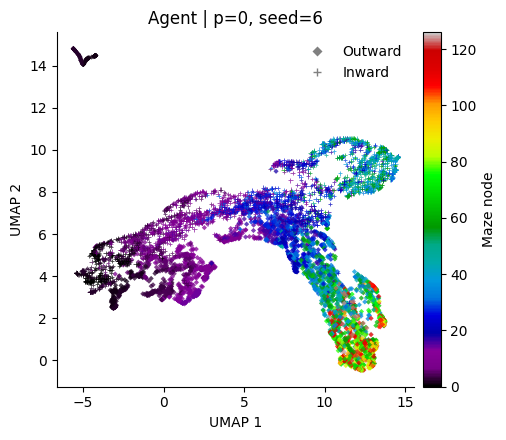

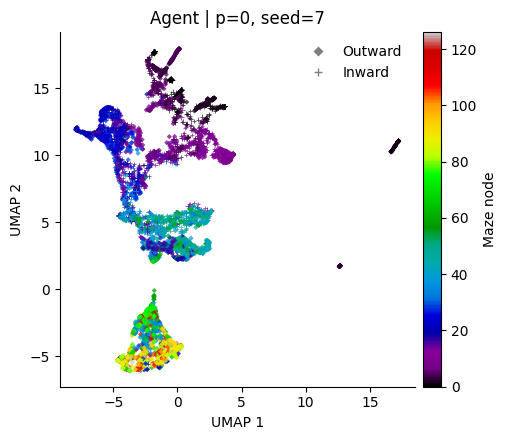

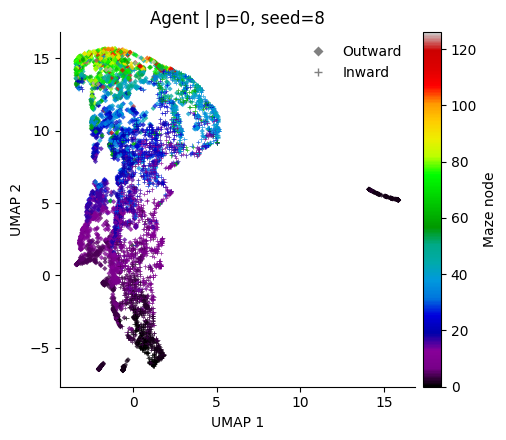

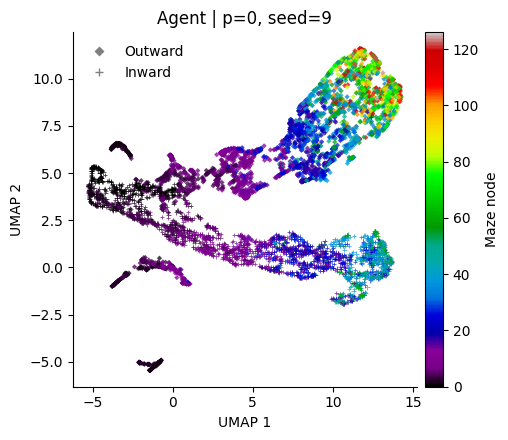

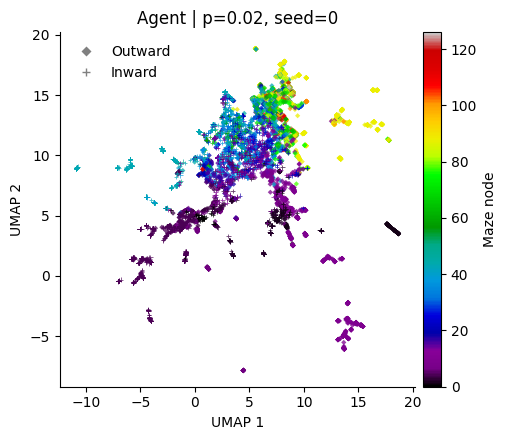

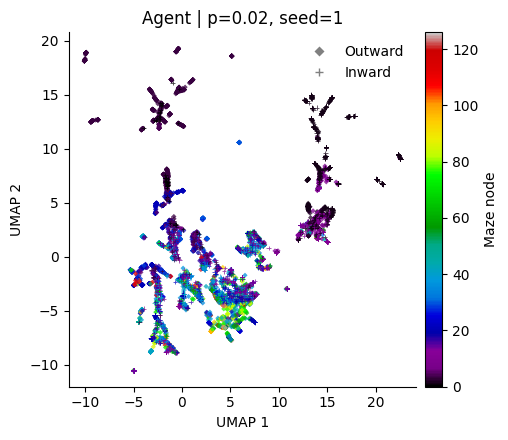

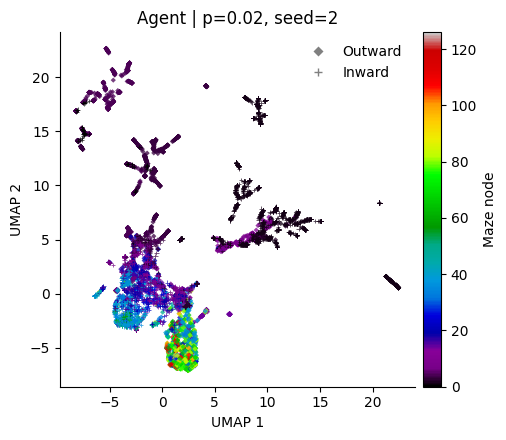

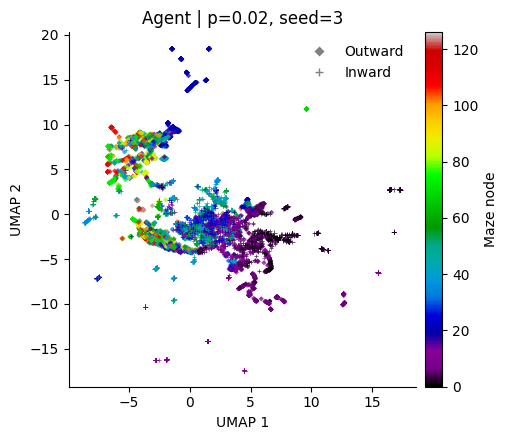

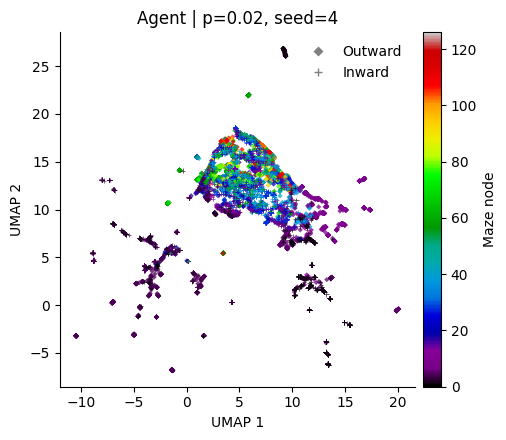

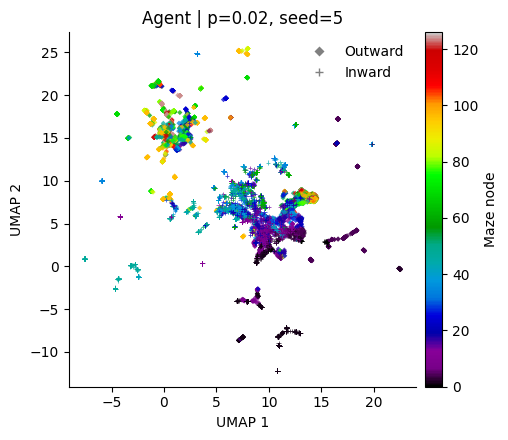

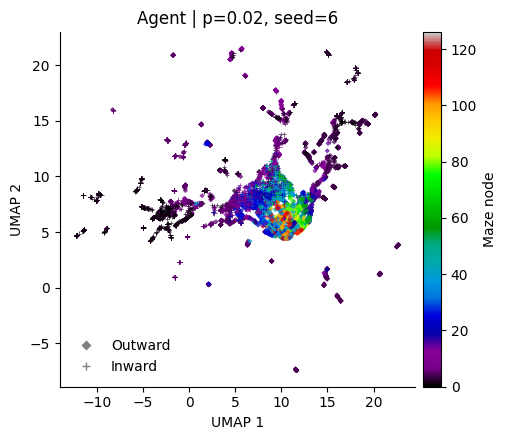

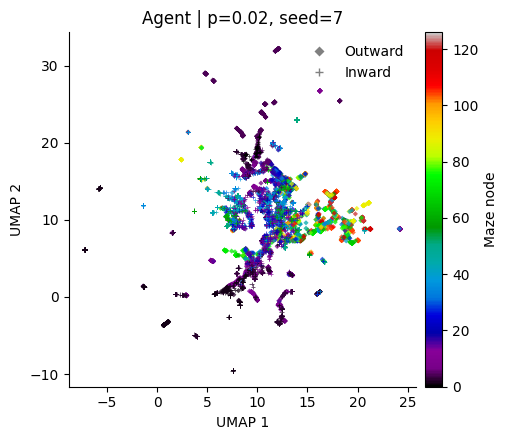

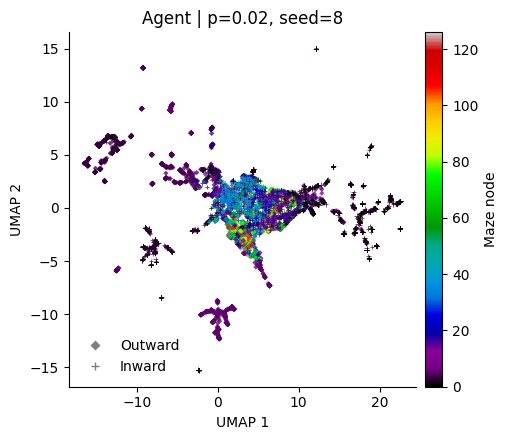

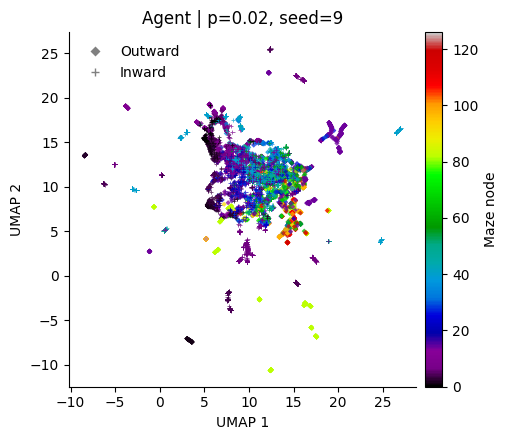

In [10]:
def plot_agent_umap(p, seed, save=True):

    umap_path = get_umap_path(p, seed)

    with open(umap_path, "rb") as f:
        saved = pickle.load(f)

    Z = np.asarray(saved["Z_umap"])

    nodes = np.asarray(
        saved["nodes_used"], dtype=int
    )

    prev_nodes = np.asarray(
        saved["prev_nodes_used"], dtype=int
    )

    # Direction determined ONLY by source/target
    valid = prev_nodes >= 0

    outward = valid & (nodes > prev_nodes)
    inward = valid & (nodes < prev_nodes)

    # Node coloring
    norm = Normalize(
        vmin=np.min(nodes),
        vmax=np.max(nodes),
    )

    cmap = plt.get_cmap("nipy_spectral")

    fig, ax = plt.subplots(figsize=(5.2, 4.5))

    # Outward: diamonds
    ax.scatter(
        Z[outward, 0],
        Z[outward, 1],
        c=nodes[outward],
        cmap=cmap,
        norm=norm,
        marker="D",
        s=7,
        alpha=0.75,
        linewidths=0,
        rasterized=True,
        zorder=1,
    )

    # Inward: plus signs
    ax.scatter(
        Z[inward, 0],
        Z[inward, 1],
        c=nodes[inward],
        cmap=cmap,
        norm=norm,
        marker="+",
        s=10,
        alpha=0.75,
        linewidths=0.6,
        rasterized=True,
        zorder=2,
    )

    # Colorbar
    sm = ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])

    cbar = fig.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label("Maze node")

    # Direction legend
    handles = [
        Line2D(
            [], [],
            linestyle="none",
            marker="D",
            markersize=5,
            markerfacecolor="gray",
            markeredgecolor="none",
            label="Outward",
        ),
        Line2D(
            [], [],
            linestyle="none",
            marker="+",
            markersize=6,
            color="gray",
            label="Inward",
        ),
    ]

    ax.legend(
        handles=handles,
        frameon=False,
        loc="best",
    )

    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")

    ax.set_title(
        f"Agent | p={p:g}, seed={seed}"
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.tight_layout()

    if save:
        p_str = format_p(p).replace(".", "p")

        fig.savefig(
            UMAP_DIR / f"agent_zp_p_{p_str}_seed_{seed}.svg",
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)


# ============================================================
# Plot all seeds for both p values
# ============================================================

for p in P_VALUES:
    for seed in SEEDS:
        plot_agent_umap(p, seed)

p=0.0, seed=9 | Plotted=3000 | Outward=1537 | Inward=1463


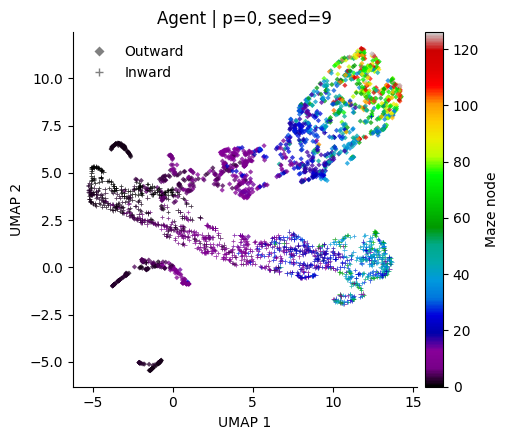

p=0.02, seed=0 | Plotted=3000 | Outward=1575 | Inward=1425


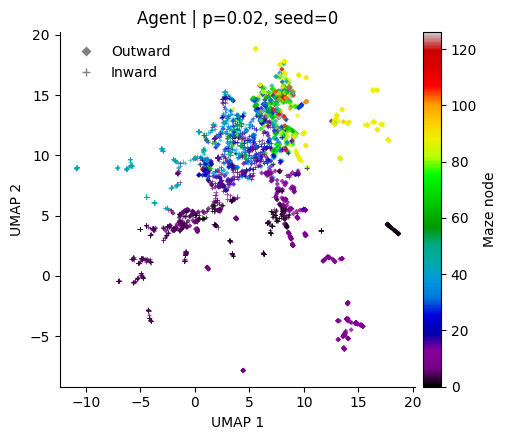

In [16]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D


def plot_agent_umap_sample(p, seed, n_points=1000):

    # Load previously fitted UMAP
    with open(get_umap_path(p, seed), "rb") as f:
        saved = pickle.load(f)

    Z = np.asarray(saved["Z_umap"])
    nodes = np.asarray(saved["nodes_used"], dtype=int)
    prev_nodes = np.asarray(saved["prev_nodes_used"], dtype=int)

    # Randomly select points FOR PLOTTING ONLY
    rng = np.random.default_rng(42 + seed)

    idx = rng.choice(
        len(Z),
        size=min(n_points, len(Z)),
        replace=False,
    )

    Z = Z[idx]
    nodes = nodes[idx]
    prev_nodes = prev_nodes[idx]

    # Direction from saved nodes
    outward = (prev_nodes >= 0) & (nodes > prev_nodes)
    inward = (prev_nodes >= 0) & (nodes < prev_nodes)

    print(
        f"p={p}, seed={seed} | "
        f"Plotted={len(Z)} | "
        f"Outward={outward.sum()} | "
        f"Inward={inward.sum()}"
    )

    # Same color mapping across both figures
    norm = Normalize(vmin=0, vmax=126)
    cmap = plt.get_cmap("nipy_spectral")

    fig, ax = plt.subplots(figsize=(5.2, 4.5))

    # Outward: diamonds
    ax.scatter(
        Z[outward, 0],
        Z[outward, 1],
        c=nodes[outward],
        cmap=cmap,
        norm=norm,
        marker="D",
        s=7,
        alpha=0.75,
        linewidths=0,
        rasterized=True,
        zorder=1,
    )

    # Inward: plus signs
    ax.scatter(
        Z[inward, 0],
        Z[inward, 1],
        c=nodes[inward],
        cmap=cmap,
        norm=norm,
        marker="+",
        s=10,
        alpha=0.75,
        linewidths=0.6,
        rasterized=True,
        zorder=2,
    )

    sm = ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])

    cbar = fig.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label("Maze node")

    handles = [
        Line2D(
            [], [], linestyle="none",
            marker="D", markersize=5,
            markerfacecolor="gray",
            markeredgecolor="none",
            label="Outward",
        ),
        Line2D(
            [], [], linestyle="none",
            marker="+", markersize=6,
            color="gray",
            label="Inward",
        ),
    ]

    ax.legend(
        handles=handles,
        frameon=False,
        loc="best",
    )

    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
    ax.set_title(f"Agent | p={p:g}, seed={seed}")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.tight_layout()

    # Save only the sampled visualization
    save_path = (
        UMAP_DIR
        / f"agent_zp_p_{str(p).replace('.', 'p')}_seed_{seed}_plot{n_points}.svg"
    )

    fig.savefig(save_path, bbox_inches="tight")

    plt.show()
    plt.close(fig)


# Plot the two requested conditions
plot_agent_umap_sample(p=0.0, seed=9, n_points=3000)
plot_agent_umap_sample(p=0.02, seed=0, n_points=3000)

# Mice

In [1]:
%pip install --user --upgrade threadpoolctl

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
  Obtaining dependency information for threadpoolctl from https://files.pythonhosted.org/packages/54/1b/831f2de4840a25db1dd7b1afea433ccafe6bb10aca07e13264f2079462d0/threadpoolctl-3.8.0-py3-none-any.whl.metadata
  Attempting uninstall: threadpoolctl
    Found existing installation: threadpoolctl 3.7.0
    Uninstalling threadpoolctl-3.7.0:
      Successfully uninstalled threadpoolctl-3.7.0

[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install --user numba

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com

[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path
import numpy as np
import pickle
import re
import umap
import matplotlib.pyplot as plt

from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D

# MICE = ["B5", "C8", "F2a", "A1b", "B3", "B4"]
# MICE = ["A1b", "B3", "B4"]
MICE = ["B5"]

# Existing mouse data directories
MOUSE_RUN_DIRS = {
    mouse: (
        Path.home()
        / "scratch"
        / "binary_maze_data"
        / "runs_20_window"
        / "water_sparsity_0.1_hdim_64_zdim_16_beta1e-3_lr1e-3_1e-3_1e-3"
        / mouse
    )
    for mouse in MICE
}


UMAP_PARAMS = dict(
    n_components=2,
    n_neighbors=30,
    min_dist=0.1,
    metric="euclidean",
    random_state=42,
)

N_LAST_STEPS = 3000

MOUSE_UMAP_DIR = (
    Path.cwd()
    / "paper_figures"
    / "mouse_prior_umaps_last3000"
)

MOUSE_UMAP_DIR.mkdir(parents=True, exist_ok=True)

def get_mouse_umap_path(mouse):
    return MOUSE_UMAP_DIR / f"{mouse}_zp_last3000.pkl"

In [4]:
def load_mouse_last_steps(mouse, n_steps=3000):

    run_dir = MOUSE_RUN_DIRS[mouse]

    files = []

    for path in run_dir.glob("bout_*_metrics.npz"):
        match = re.fullmatch(
            r"bout_(\d+)_metrics\.npz",
            path.name,
        )

        if match:
            files.append((int(match.group(1)), path))

    files.sort(key=lambda x: x[0])

    if not files:
        raise ValueError(f"No bout files in {run_dir}")

    z_parts = []
    nodes_parts = []
    prev_parts = []

    collected = 0

    # Start from the most recent bout
    for bout_id, path in reversed(files):

        with np.load(path, allow_pickle=True) as data:
            z = np.asarray(data["z_p"])
            nodes = np.asarray(
                data["target_node"], dtype=int
            )

        if len(z) != len(nodes):
            raise ValueError(
                f"Alignment mismatch in {path}"
            )

        # Previous node WITHIN each bout
        prev_nodes = np.full(len(nodes), -1, dtype=int)
        prev_nodes[1:] = nodes[:-1]

        # Take only as many steps as still needed
        take = min(n_steps - collected, len(z))

        if take == 0:
            continue

        z_parts.append(z[-take:])
        nodes_parts.append(nodes[-take:])
        prev_parts.append(prev_nodes[-take:])

        collected += take

        if collected >= n_steps:
            break

    if collected < n_steps:
        raise ValueError(
            f"{mouse}: only {collected} steps available"
        )

    # Restore chronological order
    Z = np.concatenate(z_parts[::-1], axis=0)
    nodes = np.concatenate(nodes_parts[::-1])
    prev_nodes = np.concatenate(prev_parts[::-1])

    return Z, nodes, prev_nodes


# ============================================================
# Fit and save UMAP for each mouse
# ============================================================

for mouse in MICE:

    Z, nodes, prev_nodes = load_mouse_last_steps(
        mouse,
        n_steps=N_LAST_STEPS,
    )
    print('loaded', mouse)

    reducer = umap.UMAP(**UMAP_PARAMS)
    Z_umap = reducer.fit_transform(Z)
    
    print('reduced', mouse)
    saved = {
        "Z_umap": Z_umap,
        "nodes_used": nodes,
        "prev_nodes_used": prev_nodes,
        "mouse": mouse,
        "z_key": "z_p",
        "n_last_steps": N_LAST_STEPS,
    }

    with open(get_mouse_umap_path(mouse), "wb") as f:
        pickle.dump(saved, f)

    outward = (prev_nodes >= 0) & (nodes > prev_nodes)
    inward = (prev_nodes >= 0) & (nodes < prev_nodes)

    print(
        f"{mouse} | Steps={len(Z)} | "
        f"Outward={outward.sum()} | "
        f"Inward={inward.sum()}"
    )

print("Mouse UMAPs saved.")

loaded B5


/storage/home/hcoda1/9/kshilova3/.local/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


reduced B5
B5 | Steps=2500 | Outward=1219 | Inward=1251
Mouse UMAPs saved.


In [17]:
def load_mouse_last_bouts(mouse, bout_fraction=0.20):

    run_dir = MOUSE_RUN_DIRS[mouse]

    files = []

    for path in run_dir.glob("bout_*_metrics.npz"):
        match = re.fullmatch(
            r"bout_(\d+)_metrics\.npz",
            path.name,
        )

        if match:
            files.append((int(match.group(1)), path))

    files.sort(key=lambda x: x[0])

    if not files:
        raise ValueError(f"No bout files in {run_dir}")

    # Select the last 20% of bouts
    n_total_bouts = len(files)

    n_selected_bouts = max(
        1,
        int(np.ceil(n_total_bouts * bout_fraction))
    )

    selected_files = files[-n_selected_bouts:]

    z_parts = []
    nodes_parts = []
    prev_parts = []

    # Load selected bouts in chronological order
    for bout_id, path in selected_files:

        with np.load(path, allow_pickle=True) as data:
            z = np.asarray(data["z_p"])
            nodes = np.asarray(
                data["target_node"], dtype=int
            )

        if len(z) != len(nodes):
            raise ValueError(
                f"Alignment mismatch in {path}"
            )

        # Previous node WITHIN each bout
        prev_nodes = np.full(
            len(nodes), -1, dtype=int
        )
        prev_nodes[1:] = nodes[:-1]

        z_parts.append(z)
        nodes_parts.append(nodes)
        prev_parts.append(prev_nodes)

    # Concatenate all selected bouts
    Z = np.concatenate(z_parts, axis=0)
    nodes = np.concatenate(nodes_parts)
    prev_nodes = np.concatenate(prev_parts)

    print(
        f"{mouse}: {n_selected_bouts}/{n_total_bouts} bouts, "
        f"{len(Z)} transitions"
    )

    return Z, nodes, prev_nodes, n_selected_bouts, n_total_bouts


# ============================================================
# Fit and save UMAP for each mouse — last 20% of bouts
# ============================================================

BOUT_FRACTION = 0.2

for mouse in MICE:

    Z, nodes, prev_nodes, n_selected, n_total = (
        load_mouse_last_bouts(
            mouse,
            bout_fraction=BOUT_FRACTION,
        )
    )

    print("loaded", mouse)

    reducer = umap.UMAP(**UMAP_PARAMS)
    Z_umap = reducer.fit_transform(Z)

    print("reduced", mouse)

    saved = {
        "Z_umap": Z_umap,
        "nodes_used": nodes,
        "prev_nodes_used": prev_nodes,
        "mouse": mouse,
        "z_key": "z_p",
        "bout_fraction": BOUT_FRACTION,
        "n_selected_bouts": n_selected,
        "n_total_bouts": n_total,
        "n_steps": len(Z),
    }

    with open(get_mouse_umap_path(mouse), "wb") as f:
        pickle.dump(saved, f)

    outward = (prev_nodes >= 0) & (nodes > prev_nodes)
    inward = (prev_nodes >= 0) & (nodes < prev_nodes)

    print(
        f"{mouse} | Steps={len(Z)} | "
        f"Outward={outward.sum()} | "
        f"Inward={inward.sum()}"
    )

print("Mouse UMAPs saved.")

B5: 37/183 bouts, 3226 transitions
loaded B5


/storage/home/hcoda1/9/kshilova3/.local/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


reduced B5
B5 | Steps=3226 | Outward=1576 | Inward=1613
Mouse UMAPs saved.
